In [31]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))

In [32]:
in_dir <- "../../results/09_analysis_podocyte_niche/05_create_bulk"
out_dir <- "../../results/09_analysis_podocyte_niche/07_de_analysis_Unassigned"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [33]:
df_counts <- t(read.csv(glue::glue("{in_dir}/Unassigned_counts_bulk.csv"), row.names = 1, check.names = FALSE))
df_meta <- read.csv(glue::glue("{in_dir}/Unassigned_meta_bulk.csv"), row.names = 1, check.names = FALSE)

In [34]:
head(df_counts)

,sample_15837,sample_15852,sample_16512,sample_21022,sample_8262,sample_B23-03794-5,sample_B23-05785-7-1,sample_B23-05785-7-2,sample_X1842,sample_X1845,sample_X1899,sample_X1912
SAMD11,109,244,152,550,18,529,842,1090,686,295,979,836
NOC2L,189,249,352,594,52,657,1195,1241,1718,590,1512,2474
KLHL17,77,123,129,198,29,332,661,447,735,225,615,1060
PLEKHN1,52,86,58,143,31,91,324,214,325,90,275,611
PERM1,12,45,28,26,11,123,298,188,118,24,96,92
HES4,263,336,358,646,155,1127,2048,1777,1565,379,1230,1463


In [35]:
head(df_meta)

,group,annotation
,<chr>,<chr>
sample_15837,SRC,unassigned
sample_15852,SRC,unassigned
sample_16512,SRC,unassigned
sample_21022,SRC,unassigned
sample_8262,SRC,unassigned
sample_B23-03794-5,Normal,unassigned


In [36]:
dds <- DESeqDataSetFromMatrix(countData = df_counts,
                              colData = df_meta,
                              design = ~ group)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [37]:
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep,]

In [38]:
dds

class: DESeqDataSet 
dim: 18001 12 
metadata(1): version
assays(1): counts
rownames(18001): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(0):
colnames(12): sample_15837 sample_15852 ... sample_X1899 sample_X1912
colData names(2): group annotation

In [39]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [40]:
df_res1 <- results(dds, contrast = c("group", "SRC", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

df_res2 <- results(dds, contrast = c("group", "LN", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

write.csv(df_res1, glue::glue("{out_dir}/de_results_SRC_vs_Normal.csv"))
write.csv(df_res2, glue::glue("{out_dir}/de_results_LN_vs_Normal.csv"))

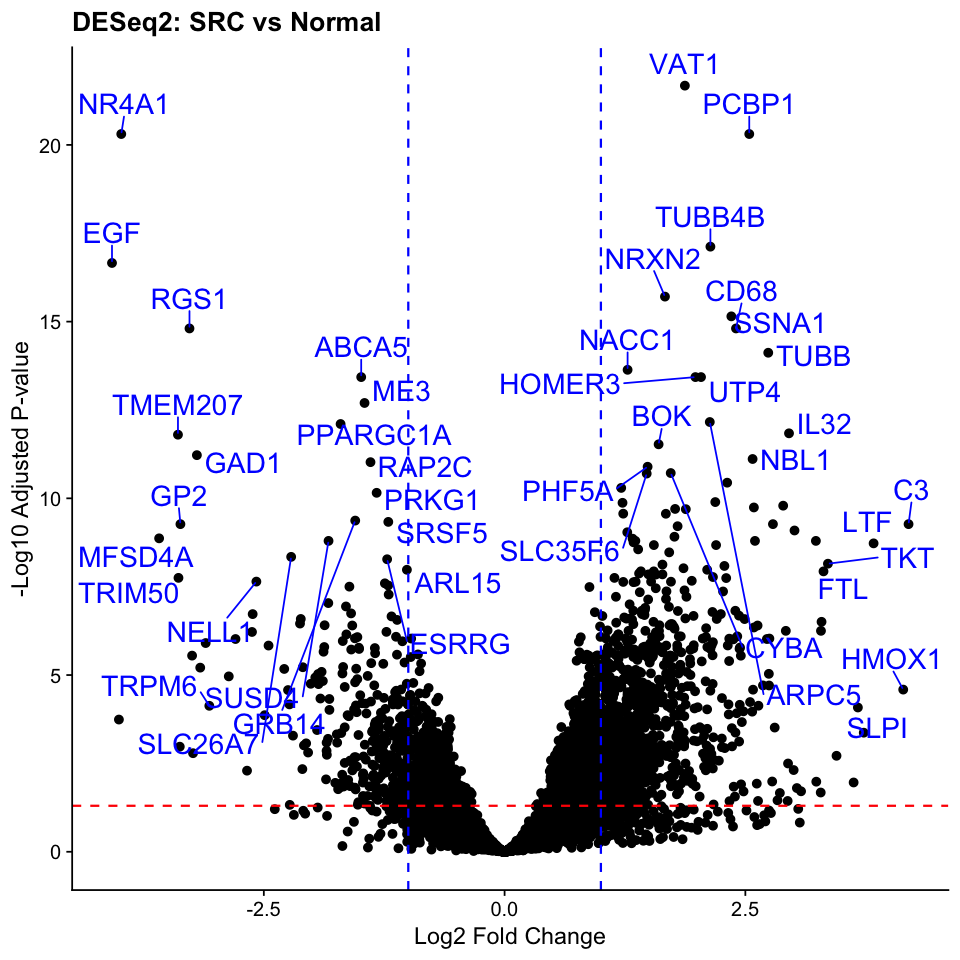

In [41]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res1, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res1, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: SRC vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_SRC_vs_Normal.png"), 
width = 8, height = 8)

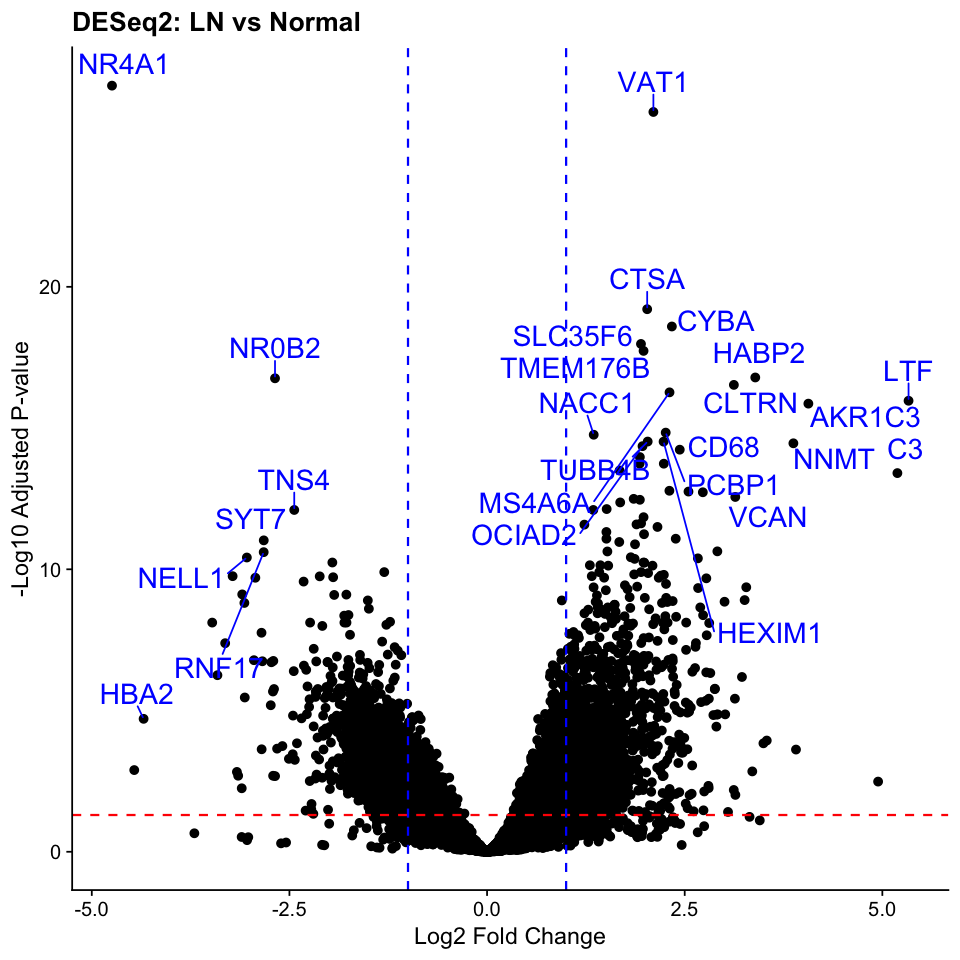

In [42]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res2, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res2, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: LN vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_LN_vs_Normal.png"), 
width = 8, height = 8)

In [43]:
options(repr.plot.width = 4, repr.plot.height = 4)

vsd <- vst(dds, blind = FALSE)  # or use rlog(dds)

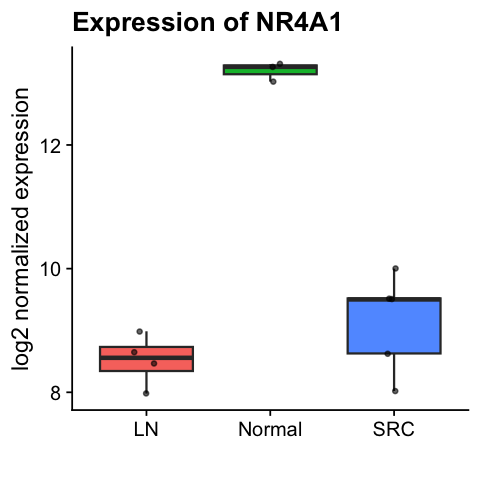

In [44]:
plot_df <- data.frame(
  expression = assay(vsd)["NR4A1", ],
  group = colData(dds)$group
)

ggplot(plot_df, aes(x = group, y = expression, fill = group)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "NR4A1"), y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")

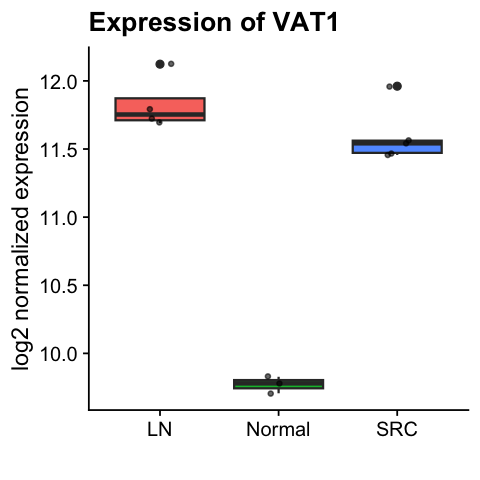

In [45]:
plot_df <- data.frame(
  expression = assay(vsd)["VAT1", ],
  group = colData(dds)$group
)

ggplot(plot_df, aes(x = group, y = expression, fill = group)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "VAT1"), y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")